# AI651 Assignment 3 — Q1 & Q2: analytical questions with NumPy / PyTorch verification
**Student:** Huzaifa | **Roll No:** 25280009 | **Course:** AI651 Deep Learning for Space, Time and Graphs (Fall 2026) | **Assignment 3**

Every claim written below is verified numerically in the code cells. All numbers used in the report are saved to `results/q1_results.json` and `results/q2_results.json`; all figures to `figures/`.

In [1]:
import json, itertools, random, pathlib, math
import numpy as np
import torch, torch.nn as nn
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True)
print('Global seed =', SEED)

RES = pathlib.Path('../results'); FIG = pathlib.Path('../figures')
RES.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
q1, q2 = {}, {}

/home/huzaifa/miniconda3/envs/pa1/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Global seed = 42


# Question 1 — What does a sum remember?
## Q1(a) — Affine message $\phi(x)=wx+c$
**Derivation.** For a neighbourhood $\mathcal N(v)$ with $n_v=|\mathcal N(v)|$ and $S_v=\sum_{u\in\mathcal N(v)}x_u$:

$$\sum_{u\in\mathcal N(v)}\phi(x_u)=\sum_{u}(w x_u+c)=w\sum_u x_u+c\sum_u 1=w\,S_v+c\,n_v .$$

**Why equal $(n_v,S_v)$ forces equal outputs.** $h_v=\rho(\sum_u\phi(x_u))=\rho(wS_v+cn_v)$. The nonlinearity $\rho$ is applied *after* aggregation and there is no degree normalisation, so the only input to $\rho$ is the single scalar $wS_v+cn_v$. If two neighbourhoods have the same $(n_v,S_v)$ this scalar is the same for **every** $(w,c)$, hence $\rho$ receives the same input and returns the same output for **every** function $\rho$ (any MLP, ReLU, tanh, …). The layer is blind to everything except $(n_v,S_v)$ — in particular to *how many* neighbours are steady (0), because a 0 contributes only through $c$ (i.e. through $n_v$), which is indistinguishable from the contribution of a $+1$ and a $-1$ that cancel.

**Construction.** $\mathcal N_1=\{+1,-1,0,0\}$ and $\mathcal N_2=\{0,0,0,0\}$ both have $n_v=4$, $S_v=0$ but have **2** vs **4** steady neighbours.

In [2]:
N1 = np.array([+1, -1, 0, 0]); N2 = np.array([0, 0, 0, 0])
print('N1: n=%d S=%d steady=%d | N2: n=%d S=%d steady=%d' % (len(N1), N1.sum(), (N1==0).sum(), len(N2), N2.sum(), (N2==0).sum()))
assert len(N1)==len(N2) and N1.sum()==N2.sum() and (N1==0).sum()!=(N2==0).sum()

def random_rho(seed):
    g = torch.Generator().manual_seed(seed)
    return nn.Sequential(nn.Linear(1,16), nn.Tanh(), nn.Linear(16,16), nn.ReLU(), nn.Linear(16,3)).double()

rng = np.random.default_rng(SEED)
max_gap = 0.0; max_gap_formula = 0.0
for trial in range(2000):
    w, c = rng.normal(size=2) * 3
    rho = random_rho(trial)
    agg = lambda nb: torch.tensor([[ (w*nb + c).sum() ]], dtype=torch.double)
    # check algebraic identity sum phi = w S + c n  and identical outputs
    for nb in (N1, N2):
        assert np.isclose((w*nb + c).sum(), w*nb.sum() + c*len(nb))
    with torch.no_grad():
        gap = (rho(agg(N1)) - rho(agg(N2))).abs().max().item()
    max_gap = max(max_gap, gap)
    # rho only sees w*S + c*n: feed the closed form (bit-identical input for N1 and N2) -> exactly equal outputs
    f = lambda nb: torch.tensor([[w*nb.sum() + c*len(nb)]], dtype=torch.double)
    with torch.no_grad():
        max_gap_formula = max(max_gap_formula, (rho(f(N1)) - rho(f(N2))).abs().max().item())
print('max |h(N1)-h(N2)| over 2000 random (w, c, rho): summing messages = %.2e (float round-off only), closed form w*S+c*n = %.1e' % (max_gap, max_gap_formula))
assert max_gap < 1e-12 and max_gap_formula == 0.0
q1['a'] = dict(N1=N1.tolist(), N2=N2.tolist(), n=4, S=0, steady_N1=int((N1==0).sum()), steady_N2=int((N2==0).sum()),
               n_random_trials=2000, max_output_gap_sum_of_messages=max_gap, max_output_gap_closed_form=max_gap_formula)

N1: n=4 S=0 steady=2 | N2: n=4 S=0 steady=4


max |h(N1)-h(N2)| over 2000 random (w, c, rho): summing messages = 2.22e-16 (float round-off only), closed form w*S+c*n = 0.0e+00


## Q1(b) — A single number that remembers all three counts
Let $n_-,n_0,n_+$ be the numbers of slowing (−1), steady (0), speeding (+1) neighbours, $1\le n_-+n_0+n_+\le K$. Choose base $B=K+1$ and

$$\phi(-1)=1,\qquad \phi(0)=B,\qquad \phi(+1)=B^2 .$$

Then the aggregated message is $s=n_-+n_0\,B+n_+\,B^2$. Each count satisfies $0\le n_\bullet\le K<B$, i.e. each is a valid base-$B$ digit, so **no carries** occur and $(n_+,n_0,n_-)$ are exactly the base-$B$ digits of $s$ (uniqueness of base-$B$ representation). Decoding:

$$n_-=s\bmod B,\qquad n_0=\lfloor s/B\rfloor\bmod B,\qquad n_+=\lfloor s/B^2\rfloor .$$

(The top digit needs no `mod` since $n_+\le K<B$ and there is no fourth digit.) The base must be at least $K+1$: with base $K$ a count of $K$ would carry into the next digit. For $K=8$: $B=9$, $\phi=(1,9,81)$.

**Counting non-steady neighbours.** Take $\phi(x)=x^2$ (or $|x|$): $\phi(\pm1)=1$, $\phi(0)=0$, so $\sum_u\phi(x_u)=n_-+n_+$ for any neighbourhood size.

In [3]:
K = 8; B = K + 1
phi = {-1: 1, 0: B, 1: B**2}
triples = [(n1, n2, n3) for n1 in range(K+1) for n2 in range(K+1) for n3 in range(K+1) if 1 <= n1+n2+n3 <= K]   # (slow, steady, up)
print('K =', K, ' B =', B, ' phi =', phi)
print('number of count triples with 1 <= n1+n2+n3 <= %d : %d' % (K, len(triples)))
assert len(triples) == math.comb(K+3, 3) - 1   # all compositions of <=K into 3 parts minus the empty one

sums = {}
for (ns, n0, nu) in triples:
    # build an actual neighbourhood and add up the scalar messages
    nbhd = [-1]*ns + [0]*n0 + [1]*nu
    s = sum(phi[x] for x in nbhd)
    # decode
    dec = (s % B, (s // B) % B, s // B**2)
    assert dec == (ns, n0, nu), (s, dec, (ns, n0, nu))
    assert s not in sums, 'collision!'
    sums[s] = (ns, n0, nu)
print('all %d sums distinct: %s ; decoding exact for every triple: True' % (len(sums), len(set(sums)) == len(triples)))
assert len(set(sums)) == len(triples)

# non-steady count with phi(x)=x^2 over all neighbourhoods up to size K
for (ns, n0, nu) in triples:
    nbhd = np.array([-1]*ns + [0]*n0 + [1]*nu)
    assert (nbhd**2).sum() == ns + nu == np.abs(nbhd).sum()
print('phi(x)=x^2 sum == #non-steady for all', len(triples), 'triples')
q1['b'] = dict(K=K, B=B, phi={str(k): v for k, v in phi.items()}, n_triples=len(triples), all_sums_distinct=True,
               decoding_exact=True, max_sum=int(max(sums)), min_sum=int(min(sums)), nonsteady_phi_x2_verified=True)

K = 8  B = 9  phi = {-1: 1, 0: 9, 1: 81}
number of count triples with 1 <= n1+n2+n3 <= 8 : 164
all 164 sums distinct: True ; decoding exact for every triple: True
phi(x)=x^2 sum == #non-steady for all 164 triples


## Q1(c) — Sum vs Mean vs Max with one-hot messages
Messages $\phi(-1)=(1,0,0)$, $\phi(0)=(0,1,0)$, $\phi(+1)=(0,0,1)$. For a neighbourhood with counts $(n_1,n_2,n_3)$ (slowing, steady, speeding), $n=n_1+n_2+n_3\in[1,8]$:
* **Sum** $=(n_1,n_2,n_3)$; * **Mean** $=(n_1,n_2,n_3)/n$; * **Max** $=(\mathbb 1[n_1>0],\mathbb 1[n_2>0],\mathbb 1[n_3>0])$.

Aggregators are permutation-invariant, so a neighbourhood is fully described by its count triple. A task is solvable by *some* $\rho$ **iff** the correct answer is a function of the aggregated vector, i.e. constant within each group of neighbourhoods that share the same vector. The brute force below enumerates all 164 count triples (sizes 1..8) and checks this exactly.

In [4]:
ONEHOT = {-1: np.array([1,0,0]), 0: np.array([0,1,0]), 1: np.array([0,0,1])}
def agg_sum(nb):  return np.sum([ONEHOT[x] for x in nb], axis=0)
def agg_mean(nb): return np.mean([ONEHOT[x] for x in nb], axis=0)
def agg_max(nb):  return np.max([ONEHOT[x] for x in nb], axis=0)
AGG = {'Sum': agg_sum, 'Mean': agg_mean, 'Max': agg_max}
TASK = {'(i) #steady':          lambda c: c[1],
        '(ii) >half slowing':   lambda c: int(c[0] > sum(c) / 2),
        '(iii) any slowing':    lambda c: int(c[0] > 0)}

from collections import defaultdict
table, counterex = {}, {}
for tname, tf in TASK.items():
    for aname, af in AGG.items():
        groups = defaultdict(list)
        for c in triples:
            nb = [-1]*c[0] + [0]*c[1] + [1]*c[2]
            vec = tuple(np.round(af(nb), 12))
            groups[vec].append((c, tf(c)))
        bad = [(v, g) for v, g in groups.items() if len({a for _, a in g}) > 1]
        table[(tname, aname)] = (len(bad) == 0)
        if bad:
            # choose a smallest-size conflicting pair as the human-readable example
            v, g = min(bad, key=lambda vg: min(sum(c) for c, _ in vg[1]))
            (c1, a1) = g[0]; c2, a2 = next((c, a) for c, a in g if a != a1)
            counterex[(tname, aname)] = dict(vector=[float(x) for x in v], nbhd1=([-1]*c1[0]+[0]*c1[1]+[1]*c1[2]), ans1=a1,
                                            nbhd2=([-1]*c2[0]+[0]*c2[1]+[1]*c2[2]), ans2=a2)
        print('%-20s %-5s possible=%-5s  (%d groups, %d conflicting)' % (tname, aname, table[(tname, aname)], len(groups), len(bad)))

expected = {('(i) #steady','Sum'):True, ('(i) #steady','Mean'):False, ('(i) #steady','Max'):False,
            ('(ii) >half slowing','Sum'):True, ('(ii) >half slowing','Mean'):True, ('(ii) >half slowing','Max'):False,
            ('(iii) any slowing','Sum'):True, ('(iii) any slowing','Mean'):True, ('(iii) any slowing','Max'):True}
assert table == expected, 'brute force disagrees with expected table'
print('\nBrute-force result matches the expected 3x3 table.')

(i) #steady          Sum   possible=True   (164 groups, 0 conflicting)
(i) #steady          Mean  possible=False  (118 groups, 15 conflicting)
(i) #steady          Max   possible=False  (7 groups, 4 conflicting)
(ii) >half slowing   Sum   possible=True   (164 groups, 0 conflicting)
(ii) >half slowing   Mean  possible=True   (118 groups, 0 conflicting)
(ii) >half slowing   Max   possible=False  (7 groups, 3 conflicting)
(iii) any slowing    Sum   possible=True   (164 groups, 0 conflicting)
(iii) any slowing    Mean  possible=True   (118 groups, 0 conflicting)
(iii) any slowing    Max   possible=True   (7 groups, 0 conflicting)

Brute-force result matches the expected 3x3 table.


### Explicit tests for every "Yes" (verified against ground truth on all 164 neighbourhoods) and explicit counter-example pairs for every "No"

In [5]:
yes_tests = {
 ('(i) #steady','Sum'):        lambda v: v[1],                      # coordinate 2 is exactly the steady count
 ('(ii) >half slowing','Sum'): lambda v: int(v[0] > v[1] + v[2]),   # n = v0+v1+v2, so n1 > n/2  <=>  v0 > v1+v2
 ('(ii) >half slowing','Mean'):lambda v: int(v[0] > 0.5),           # mean coord 1 = n1/n
 ('(iii) any slowing','Sum'):  lambda v: int(v[0] > 0),
 ('(iii) any slowing','Mean'): lambda v: int(v[0] > 0),
 ('(iii) any slowing','Max'):  lambda v: int(v[0] == 1),
}
for (tname, aname), rho in yes_tests.items():
    for c in triples:
        nb = [-1]*c[0] + [0]*c[1] + [1]*c[2]
        assert rho(AGG[aname](nb)) == TASK[tname](c), (tname, aname, c)
    print('verified rho for', tname, aname)

rows = []
for (tname, aname), ce in counterex.items():
    print('\nNO  %s / %s:\n   vector %s\n   N_A=%s -> %s\n   N_B=%s -> %s' % (tname, aname, ce['vector'], ce['nbhd1'], ce['ans1'], ce['nbhd2'], ce['ans2']))
# hand-picked readable examples quoted in the report
HAND = {
 'steady_mean':  dict(A=[-1, 0, 1], B=[-1, -1, 0, 0, 1, 1]),            # mean (1/3,1/3,1/3); steady 1 vs 2
 'steady_max':   dict(A=[0], B=[0, 0]),                                  # max (0,1,0); steady 1 vs 2
 'half_max':     dict(A=[-1, 0], B=[-1, -1, 0]),                         # max (1,1,0); slowing 1/2 (not >half) vs 2/3 (>half)
}
for k, d in HAND.items():
    A_, B_ = d['A'], d['B']
    f = agg_mean if 'mean' in k else agg_max
    print(k, 'vector A', f(A_), 'vector B', f(B_))
    assert np.allclose(f(A_), f(B_))
assert TASK['(i) #steady'](tuple([(np.array(HAND['steady_mean']['A'])==v).sum() for v in (-1,0,1)])) == 1
q1['c'] = dict(table={f'{t}|{a}': bool(v) for (t, a), v in table.items()},
               counterexamples={f'{t}|{a}': ce for (t, a), ce in counterex.items()},
               n_neighbourhoods_checked=len(triples))
json.dump(q1, open(RES/'q1_results.json', 'w'), indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

verified rho for (i) #steady Sum
verified rho for (ii) >half slowing Sum
verified rho for (ii) >half slowing Mean
verified rho for (iii) any slowing Sum
verified rho for (iii) any slowing Mean
verified rho for (iii) any slowing Max

NO  (i) #steady / Mean:
   vector [0.0, 1.0, 0.0]
   N_A=[0] -> 1
   N_B=[0, 0] -> 2

NO  (i) #steady / Max:
   vector [0.0, 1.0, 0.0]
   N_A=[0] -> 1
   N_B=[0, 0] -> 2

NO  (ii) >half slowing / Max:
   vector [1.0, 0.0, 1.0]
   N_A=[-1, 1] -> 0
   N_B=[-1, -1, 1] -> 1
steady_mean vector A [0.33333333 0.33333333 0.33333333] vector B [0.33333333 0.33333333 0.33333333]
steady_max vector A [0 1 0] vector B [0 1 0]
half_max vector A [1 1 0] vector B [1 1 0]


### Q1(c) final table (all entries verified by the brute force above)

| Task | Method | Possible? | Reason |
|---|---|---|---|
| (i) count steady | **Sum** | **Yes** | Sum vector is $(n_1,n_2,n_3)$; $\rho$ returns coordinate 2, $n_2$. |
| | **Mean** | **No** | $\{-1,0,+1\}$ and $\{-1,-1,0,0,+1,+1\}$ both give $(\tfrac13,\tfrac13,\tfrac13)$ but have 1 and 2 steady neighbours. |
| | **Max** | **No** | $\{0\}$ and $\{0,0\}$ both give $(0,1,0)$ but have 1 and 2 steady neighbours. |
| (ii) more than half slowing | **Sum** | **Yes** | Since $n=v_1+v_2+v_3$, test $v_1>v_2+v_3$ (equivalently $2v_1>v_1+v_2+v_3$). Uses all three coordinates. |
| | **Mean** | **Yes** | Coordinate 1 equals $n_1/n$; test $m_1>0.5$. |
| | **Max** | **No** | $\{-1,0\}$ and $\{-1,-1,0\}$ both give $(1,1,0)$; slowing is 1/2 (not more than half → **No**) vs 2/3 (→ **Yes**). |
| (iii) any slowing | **Sum** | **Yes** | Test $v_1>0$ (coordinate 1). |
| | **Mean** | **Yes** | Test $m_1>0$ (coordinate 1); $n_1/n>0\iff n_1>0$. |
| | **Max** | **Yes** | Coordinate 1 equals 1 iff some neighbour is slowing; test $v_1=1$. |

# Question 2 — Which way is the slowdown moving?
Ring of 40 sensors, true rule $x_i(t+1)=x_{i+1}(t)$, i.e. `np.roll(x, -1)`.
## Q2(a)(i) — Symmetric layer fitted on one impulse
Impulse $x_{20}(0)=1$. True next snapshot: 1 at sensor 19, 0 elsewhere (incl. 20). The layer predicts $\hat x_i=a\,x_i+b(x_{i-1}+x_{i+1})$:

| sensor | prediction | correct |
|---|---|---|
| 19 | $a\cdot0+b(x_{18}+x_{20})=b$ | 1 |
| 20 | $a\cdot1+b(x_{19}+x_{21})=a$ | 0 |
| 21 | $a\cdot0+b(x_{20}+x_{22})=b$ | 0 |

All other sensors predict 0 and are correct (0). So $L(a,b)=(b-1)^2+a^2+b^2$.
$\partial L/\partial a=2a=0\Rightarrow a=0$; $\partial L/\partial b=2(b-1)+2b=4b-2=0\Rightarrow b=\tfrac12$. Hessian $=\mathrm{diag}(2,4)\succ0$ so it is the global minimum. $L_{\min}=(\tfrac12-1)^2+0+\tfrac14=\tfrac12$. The error is irreducible: sensors 19 and 21 always get the same prediction, but 19 should be 1 and 21 should be 0.

In [6]:
N_S = 40
x0 = np.zeros(N_S); x0[20] = 1
target = np.roll(x0, -1)
assert target[19] == 1 and target[20] == 0 and target.sum() == 1

# design matrix: columns = [x_i, x_{i-1}+x_{i+1}]
Xd = np.stack([x0, np.roll(x0, 1) + np.roll(x0, -1)], axis=1)
(sol, *_) = np.linalg.lstsq(Xd, target, rcond=None)
a_fit, b_fit = sol
sse = float(((Xd @ sol - target)**2).sum())
print('lstsq: a=%.6f b=%.6f SSE=%.6f' % (a_fit, b_fit, sse))
# also check with the closed-form loss and a brute-force grid
L = lambda a, b: (b-1)**2 + a**2 + b**2
aa, bb = np.meshgrid(np.linspace(-2, 2, 801), np.linspace(-2, 2, 801)); LL = L(aa, bb)
i, j = np.unravel_index(LL.argmin(), LL.shape)
print('grid minimum at a=%.3f b=%.3f L=%.4f' % (aa[i, j], bb[i, j], LL[i, j]))
assert np.isclose(a_fit, 0) and np.isclose(b_fit, 0.5) and np.isclose(sse, 0.5)
pred = Xd @ sol
print('pred at 19,20,21 =', pred[19:22], ' correct =', target[19:22])
q2 = {'a_i': dict(a=float(a_fit), b=float(b_fit), sse=sse, pred_19_20_21=pred[19:22].tolist(), target_19_20_21=target[19:22].tolist())}

lstsq: a=0.000000 b=0.500000 SSE=0.500000
grid minimum at a=0.000 b=0.500 L=0.5000
pred at 19,20,21 = [0.5 0.  0.5]  correct = [1. 0. 0.]


## Q2(a)(ii) — Apply the fitted layer 20 times to a smooth bump
With $a=0,b=\tfrac12$ the layer is $x_i\leftarrow\tfrac12(x_{i-1}+x_{i+1})$ (periodic). Compare with the true motion (`np.roll(x,-1)` each step).

pred : peak idx t=0..20 = [20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]
truth: peak idx t=0..20 = [20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
pred peak value t=0 -> t=20 : 1.0000 -> 0.4047 ; truth: 1.0000 -> 1.0000
pred  total mass t=0/t=20 : 5.0133 / 5.0133 ; truth: 5.0133 / 5.0133
pred bump std 2.000 -> 4.899 ; truth 2.000 -> 2.000


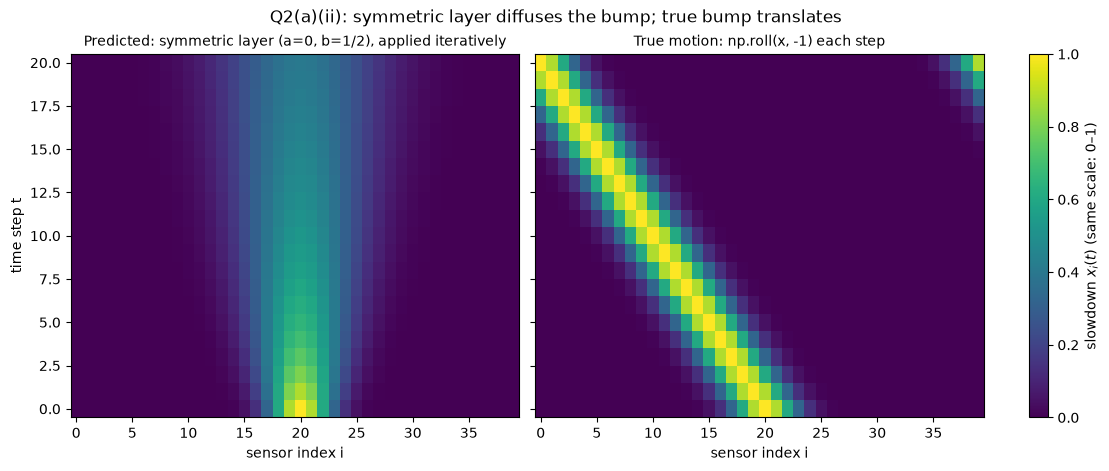

In [7]:
idx = np.arange(N_S)
bump0 = np.exp(-(idx - 20)**2 / 8)
def layer(x, a=0.0, b=0.5):  return a*x + b*(np.roll(x, 1) + np.roll(x, -1))
T = 20
P = np.zeros((T+1, N_S)); Tr = np.zeros((T+1, N_S)); P[0] = Tr[0] = bump0
for t in range(T):
    P[t+1] = layer(P[t]); Tr[t+1] = np.roll(Tr[t], -1)
com = lambda x: (x*idx).sum()/x.sum()
print('pred : peak idx t=0..20 =', P.argmax(1).tolist())
print('truth: peak idx t=0..20 =', Tr.argmax(1).tolist())
print('pred peak value t=0 -> t=20 : %.4f -> %.4f ; truth: %.4f -> %.4f' % (P[0].max(), P[-1].max(), Tr[0].max(), Tr[-1].max()))
print('pred  total mass t=0/t=20 : %.4f / %.4f ; truth: %.4f / %.4f' % (P[0].sum(), P[-1].sum(), Tr[0].sum(), Tr[-1].sum()))
# the bump width (std about its centre)
std = lambda x, c: np.sqrt((x*(idx-c)**2).sum()/x.sum())
print('pred bump std %.3f -> %.3f ; truth %.3f -> %.3f' % (std(P[0],20), std(P[-1],20), std(Tr[0],20), std(np.roll(Tr[-1], T), 20)))   # re-centre the wrapped true bump before measuring its width
assert np.array_equal(P.argmax(1), np.full(T+1, 20)) and Tr[-1].argmax() == 0
assert np.allclose(Tr[-1], np.roll(bump0, -T)) and np.isclose(Tr[-1].max(), Tr[0].max())

vmin, vmax = 0.0, 1.0
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, constrained_layout=True)
for ax, M, ttl in zip(axs, (P, Tr), ('Predicted: symmetric layer (a=0, b=1/2), applied iteratively', 'True motion: np.roll(x, -1) each step')):
    im = ax.imshow(M, aspect='auto', origin='lower', vmin=vmin, vmax=vmax, cmap='viridis', extent=[-0.5, N_S-0.5, -0.5, T+0.5])
    ax.set_title(ttl, fontsize=10); ax.set_xlabel('sensor index i');
axs[0].set_ylabel('time step t')
fig.colorbar(im, ax=axs, label='slowdown $x_i(t)$ (same scale: 0–1)')
fig.suptitle('Q2(a)(ii): symmetric layer diffuses the bump; true bump translates', fontsize=12)
fig.savefig(FIG/'q2a_heatmaps.png', dpi=160); plt.show()
q2['a_ii'] = dict(pred_peak_idx=P.argmax(1).tolist(), truth_peak_idx=Tr.argmax(1).tolist(), pred_peak_t0=float(P[0].max()), pred_peak_t20=float(P[-1].max()),
                  truth_peak_t20=float(Tr[-1].max()), truth_std_t20=float(std(np.roll(Tr[-1], T), 20)), pred_std_t0=float(std(P[0],20)), pred_std_t20=float(std(P[-1],20)),
                  mass_pred_t20=float(P[-1].sum()), mass_t0=float(P[0].sum()), vmin=vmin, vmax=vmax)

**Comparison (Q2(a)(ii)).** The predicted bump never leaves sensor 20: its peak falls from 1.00 to the value printed above and its width grows — the layer is a symmetric diffusion (averaging) filter that smooths and decays the pattern about a fixed centre and cannot tell which way it moves. The true bump keeps its exact shape and height and translates one sensor per step against traffic (peak at sensor 20 at $t=0$, at sensor 0 at $t=20$).

## Q2(b) — Direction-aware weights: $\hat x_i(t+1)=a\,x_i+w_-x_{i-1}+w_+x_{i+1}$
The truth is $x_i(t+1)=x_{i+1}(t)$, so choose $a=0,\;w_-=0,\;w_+=1$. **Verification by substitution:** $\hat x_i=0\cdot x_i+0\cdot x_{i-1}+1\cdot x_{i+1}=x_{i+1}(t)=x_i(t+1)$ for every $i$ and every input (indices mod 40). Uniqueness: three unknowns, and the three inputs $e_{i}$, $e_{i-1}$, $e_{i+1}$ already force $(a,w_-,w_+)=(0,0,1)$ exactly.

**Why this fixes (a).** In (a) both neighbours share one weight $b$, so the layer is invariant under the reflection $i\mapsto 40-i$ (without sensor IDs); sensors 19 and 21 are mirror images of an impulse at 20 and *must* receive identical predictions, whereas the truth needs 19→1 and 21→0. Giving $x_{i-1}$ and $x_{i+1}$ different weights breaks the reflection symmetry: the layer is told which neighbour is *ahead* ($i+1$) and which is behind ($i-1$), and can copy the one ahead.

**As a 1D convolution.** Kernel entries in the order that multiplies $[x_{i-1},x_i,x_{i+1}]$: **$[w_-,a,w_+]=[0,0,1]$**. PyTorch `Conv1d` computes cross-correlation (it does **not** flip the kernel), so the kernel is used as written. The ring boundary is handled with **circular padding** (`padding=1, padding_mode='circular'`), so sensor 39's right neighbour is sensor 0 and sensor 0's left neighbour is sensor 39.

In [8]:
rng = np.random.default_rng(SEED)
# substitution check on 10,000 random inputs + all one-hot inputs
Xr = np.concatenate([rng.normal(size=(10000, N_S)), np.eye(N_S)])
pred_b = 0*Xr + 0*np.roll(Xr, 1, axis=1) + 1*np.roll(Xr, -1, axis=1)
assert np.array_equal(pred_b, np.roll(Xr, -1, axis=1))
# uniqueness via least squares on random snapshots
D = np.stack([Xr.ravel(), np.roll(Xr, 1, axis=1).ravel(), np.roll(Xr, -1, axis=1).ravel()], axis=1)
sol_b = np.linalg.lstsq(D, np.roll(Xr, -1, axis=1).ravel(), rcond=None)[0]
print('lstsq recovers (a, w-, w+) =', np.round(sol_b, 10))
assert np.allclose(sol_b, [0, 0, 1])

conv = nn.Conv1d(1, 1, kernel_size=3, padding=1, padding_mode='circular', bias=False)
with torch.no_grad(): conv.weight.copy_(torch.tensor([[[0., 0., 1.]]]))
xt = torch.tensor(Xr, dtype=torch.float32).unsqueeze(1)
out = conv(xt).squeeze(1).detach().numpy()
err_conv = float(np.abs(out - np.roll(Xr, -1, axis=1)).max())
print('torch Conv1d kernel [0,0,1], circular padding: max |conv - np.roll(x,-1)| =', err_conv)
assert err_conv < 1e-6
# ring boundary spot-check
e39 = torch.zeros(1, 1, N_S); e39[0, 0, 0] = 1       # impulse at sensor 0 -> after one step must sit at sensor 39
assert conv(e39).argmax().item() == 39
# mechanics: cross-correlation => no flip. Flipped kernel [1,0,0] would shift the other way
conv_f = nn.Conv1d(1, 1, 3, padding=1, padding_mode='circular', bias=False)
with torch.no_grad(): conv_f.weight.copy_(torch.tensor([[[1., 0., 0.]]]))
e20 = torch.zeros(1, 1, N_S); e20[0, 0, 20] = 1
print('kernel [0,0,1] moves impulse 20 ->', conv(e20).argmax().item(), '; flipped kernel [1,0,0] moves it ->', conv_f(e20).argmax().item())
q2['b'] = dict(a=0, w_minus=0, w_plus=1, kernel=[0, 0, 1], n_random_inputs=int(Xr.shape[0]), lstsq=sol_b.tolist(), conv_max_abs_err=err_conv,
               impulse20_moves_to=int(conv(e20).argmax().item()))

lstsq recovers (a, w-, w+) = [-0.  0.  1.]
torch Conv1d kernel [0,0,1], circular padding: max |conv - np.roll(x,-1)| = 2.3183702779761006e-07
kernel [0,0,1] moves impulse 20 -> 19 ; flipped kernel [1,0,0] moves it -> 21


## Q2(c) — Using history with equal neighbour weights: $\hat x_i(t+1)=a\,x_i(t)+b\,(x_{i-1}(t)+x_{i+1}(t))+c\,x_i(t-1)$
### Q2(c)(i) — Backward motion $x_i(t)=x_{i+1}(t-1)$
Apply the rule one step earlier at sensor $i-1$: $x_{i-1}(t)=x_{i}(t-1)$. That rewrites the history term as a current reading: $x_i(t-1)=x_{i-1}(t)$. The target is $x_i(t+1)=x_{i+1}(t)$ and trivially

$$x_{i+1}(t)=\big[x_{i-1}(t)+x_{i+1}(t)\big]-x_{i-1}(t)=\big[x_{i-1}(t)+x_{i+1}(t)\big]-x_i(t-1).$$

Hence **$a=0,\;b=1,\;c=-1$** is exact for every consecutive pair $(x(t-1),x(t))$ produced by the backward rule. The history term cancels the *unwanted* (behind) neighbour.

### Q2(c)(ii) — Forward motion $x_i(t+1)=x_{i-1}(t)$ with the **same** $(0,1,-1)$
Under forward motion $x_{i+1}(t)=x_i(t-1)$, i.e. $x_i(t-1)=x_{i+1}(t)$. Substituting: $\hat x_i(t+1)=x_{i-1}(t)+x_{i+1}(t)-x_i(t-1)=x_{i-1}(t)+x_{i+1}(t)-x_{i+1}(t)=x_{i-1}(t)$, which equals the correct forward step $x_i(t+1)=x_{i-1}(t)$. **So the very same coefficients still work** — now the history term cancels the *other* neighbour.

In [9]:
def make_pair(direction, rng):
    """Return (x_prev, x_curr, x_next) for a random snapshot under backward (-1) or forward (+1) motion."""
    xp = rng.normal(size=N_S)
    shift = -1 if direction == 'backward' else +1       # backward: x_i(t+1)=x_{i+1}(t) = roll(-1); forward: x_i(t+1)=x_{i-1}(t) = roll(+1)
    xc = np.roll(xp, shift); xn = np.roll(xc, shift)
    return xp, xc, xn
def hist_layer(xp, xc, a=0., b=1., c=-1.):
    return a*xc + b*(np.roll(xc, 1) + np.roll(xc, -1)) + c*xp

rng = np.random.default_rng(SEED)
errs = {}
for d in ('backward', 'forward'):
    e = 0.0
    for _ in range(5000):
        xp, xc, xn = make_pair(d, rng)
        e = max(e, np.abs(hist_layer(xp, xc) - xn).max())
    errs[d] = float(e); print('%-8s motion: max |prediction - truth| over 5000 random pairs = %.2e' % (d, e))
    assert e < 1e-12

# (i) the rewriting step x_i(t-1) = x_{i-1}(t) holds under backward motion; (ii) x_i(t-1)=x_{i+1}(t) under forward motion
xp, xc, _ = make_pair('backward', rng); assert np.array_equal(xp, np.roll(xc, 1))     # x_i(t-1)=x_{i-1}(t)
xp, xc, _ = make_pair('forward', rng);  assert np.array_equal(xp, np.roll(xc, -1))    # x_i(t-1)=x_{i+1}(t)
print('identities x_i(t-1)=x_{i-1}(t) [backward] and x_i(t-1)=x_{i+1}(t) [forward] verified')

# uniqueness: least squares over backward pairs recovers (0,1,-1)
rows, ys = [], []
for _ in range(50):
    xp, xc, xn = make_pair('backward', rng)
    rows.append(np.stack([xc, np.roll(xc, 1)+np.roll(xc, -1), xp], 1)); ys.append(xn)
sol_c = np.linalg.lstsq(np.concatenate(rows), np.concatenate(ys), rcond=None)[0]
print('lstsq on backward pairs -> (a,b,c) =', np.round(sol_c, 10)); assert np.allclose(sol_c, [0, 1, -1])
q2['c'] = dict(a=0, b=1, c=-1, max_err_backward=errs['backward'], max_err_forward=errs['forward'], lstsq_backward=sol_c.tolist(), n_pairs=5000)

backward motion: max |prediction - truth| over 5000 random pairs = 8.88e-16
forward  motion: max |prediction - truth| over 5000 random pairs = 4.44e-16
identities x_i(t-1)=x_{i-1}(t) [backward] and x_i(t-1)=x_{i+1}(t) [forward] verified
lstsq on backward pairs -> (a,b,c) = [ 0.  1. -1.]


### Q2(c)(iii) — How history disambiguates direction
The spatial part $x_{i-1}(t)+x_{i+1}(t)$ is symmetric: it contains the right answer *and* the wrong one mixed together and cannot tell which is which. The **previous snapshot** carries the direction: the pair $(x(t-1),x(t))$ reveals how the pattern has just moved, because $x_i(t-1)$ equals the reading of the neighbour the pattern *came from* ($x_{i-1}(t)$ under backward motion, $x_{i+1}(t)$ under forward motion). Subtracting $x_i(t-1)$ therefore cancels exactly the neighbour that the pattern moved *away from* and leaves the other — the one the pattern moves *toward* — automatically, without any direction-dependent spatial weights. The direction information is encoded in **time** (in the temporal difference), not in asymmetric spatial weights.

Demonstration: the *same* current snapshot $x(t)$ with two different histories produces two different (and correct) predictions, whereas a purely spatial symmetric layer must output one answer for both.

In [10]:
rng = np.random.default_rng(SEED)
xc = np.zeros(N_S); xc[20] = 1.0                                 # identical current snapshot: impulse at 20
xp_back = np.roll(xc, 1)                                          # backward motion: x_i(t-1) = x_{i-1}(t)  -> previous impulse sat at sensor 21
xp_fwd = np.roll(xc, -1)                                          # forward motion:  x_i(t-1) = x_{i+1}(t)  -> previous impulse sat at sensor 19
pb, pf = hist_layer(xp_back, xc), hist_layer(xp_fwd, xc)
sym = layer(xc)                                                   # purely spatial symmetric layer (a=0,b=1/2)
print('same x(t) = impulse@20')
print(' history says backward: prediction impulse at', pb.argmax(), ' (truth', np.roll(xc, -1).argmax(), ')')
print(' history says forward : prediction impulse at', pf.argmax(), ' (truth', np.roll(xc, 1).argmax(), ')')
print(' symmetric spatial layer: values at 19,20,21 =', sym[19:22], '-> cannot choose')
assert pb.argmax() == 19 and pf.argmax() == 21 and np.allclose(pb, np.roll(xc, -1)) and np.allclose(pf, np.roll(xc, 1))
q2['c_iii'] = dict(backward_pred_at=int(pb.argmax()), forward_pred_at=int(pf.argmax()), symmetric_layer_19_20_21=sym[19:22].tolist())
json.dump(q2, open(RES/'q2_results.json', 'w'), indent=1)
print('saved results/q1_results.json and results/q2_results.json')

same x(t) = impulse@20
 history says backward: prediction impulse at 19  (truth 19 )
 history says forward : prediction impulse at 21  (truth 21 )
 symmetric spatial layer: values at 19,20,21 = [0.5 0.  0.5] -> cannot choose
saved results/q1_results.json and results/q2_results.json
